In [ ]:
# PerformIQ AI: Score Prediction, Risk Flagging and Recommendations

# **Modules covered in this notebook**
# - **Module 1: Score Prediction.** Predicts a student's expected exam score from study habits and past performance, using regression models.
# - **Module 2: Risk Flagging and Recommendations.** Converts the predicted score into a risk level (High / Medium / Low) and suggests actions a teacher can take.

# **Dataset:** `final_student_exam_performance.csv` (100,000 students, one row per student, one exam each).

# **Why this is a separate notebook:** This dataset describes student habits (study hours, attendance, sleep, etc.) for a single exam. It answers the question "What score will this student get?" 
# The other notebook (Module 3) uses a different dataset that tracks students week by week. The two problems need different data and different models, so we keep them apart. 
#     Each notebook can be run on its own.

# PART A: Understanding the data

In [ ]:
## Part A: Understanding the Data
# Before building any model we check what the data looks like: its size, types, missing values and how each factor relates to the exam score. 
# Good models start with understanding the data.

In [1]:
### 1. Imports and Loading the Data
# We import the libraries (pandas for data, matplotlib/seaborn for charts, scikit-learn for machine learning) and load the CSV. 
# The shape check confirms we have 100,000 students and 44 columns.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

df = pd.read_csv("final_student_exam_performance.csv")
print(df.shape)
df.head()

(100000, 44)


,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,...,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,...,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,...,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,...,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,...,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low


In [2]:
### 2. Structure of the Data
# `info()` shows each column's type and how many values are filled. `describe()` shows the minimum, maximum, average and spread of each column. 
# We use this to spot impossible values and to see which columns are numbers and which are text.

df.info()
print("\n--- Numeric columns summary ---")
display(df.describe().T)
print("\n--- Text columns summary ---")
display(df.describe(exclude="number").T) 

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   student_id                  100000 non-null  str    
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  str    
 3   education_level             100000 non-null  str    
 4   school_type                 100000 non-null  str    
 5   family_income               100000 non-null  str    
 6   parent_education            93474 non-null   str    
 7   urban_rural                 100000 non-null  str    
 8   previous_exam_score         100000 non-null  float64
 9   previous_gpa                92207 non-null   float64
 10  attendance_percentage       90137 non-null   float64
 11  assignment_completion_rate  100000 non-null  float64
 12  class_participation         100000 non-null  str    
 13  study_hours_per_day       

,count,mean,std,min,25%,50%,75%,max
age,100000.0,17.005740,1.999562,14.00,15.00,17.00,19.0000,20.00
previous_exam_score,100000.0,69.531033,11.379108,30.00,61.82,69.53,77.2325,100.00
previous_gpa,92207.0,2.780892,0.478218,1.00,2.46,2.78,3.1100,4.00
attendance_percentage,90137.0,84.616882,7.922485,46.34,79.21,84.75,90.1700,100.00
assignment_completion_rate,100000.0,69.724405,12.127179,20.00,61.48,69.57,77.9200,100.00
study_hours_per_day,100000.0,2.995725,1.719466,0.50,1.72,2.67,3.9100,12.00
self_study_hours,100000.0,2.094970,1.266066,0.25,1.17,1.84,2.7300,10.00
private_tuition,100000.0,0.299800,0.458173,0.00,0.00,0.00,1.0000,1.00
online_learning_hours,100000.0,2.004763,2.005719,0.00,0.58,1.38,2.7700,15.00
practice_tests_completed,100000.0,5.509170,2.501131,0.00,4.00,5.00,7.0000,20.00



--- Text columns summary ---


,count,unique,top,freq
student_id,100000,100000,STU_000001,1
gender,100000,3,Male,49130
education_level,100000,2,High School,59752
school_type,100000,3,Public,55105
family_income,100000,5,Middle,30112
parent_education,93474,5,High School,28122
urban_rural,100000,3,Urban,44963
class_participation,100000,3,Medium,50109
study_consistency,100000,3,Medium,55137
study_environment,100000,3,Quiet,49789


In [3]:
### 3. Data Quality Checks
# We check for duplicate rows and confirm that every student ID is unique (one row per student). 
# We also count missing values. Seven columns have gaps (roughly 3% to 10%). That is small enough to fill in later rather than delete rows.-

print("Duplicate rows:", df.duplicated().sum())
print("Unique student IDs:", df["student_id"].nunique(), "of", len(df))

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

missing_df = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(df) * 100).round(2)
})
print("\nTotal missing cells:", int(df.isnull().sum().sum()))
display(missing_df)

Duplicate rows: 0
Unique student IDs: 100000 of 100000

Total missing cells: 52161


,missing_count,missing_percent
attendance_percentage,9863,9.86
time_management_score,9613,9.61
notes_quality,8407,8.41
previous_gpa,7793,7.79
sleep_quality,6994,6.99
parent_education,6526,6.53
device_availability,2965,2.96


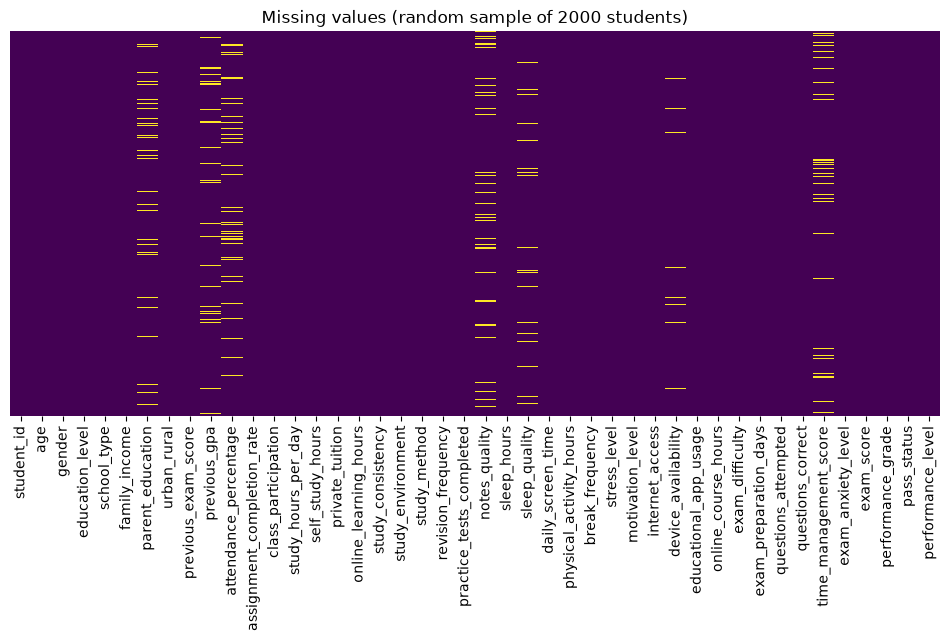

In [4]:
### 4. Where Are the Missing Values?
# The heatmap shows missing cells on a random sample of 2,000 students (plotting all 100,000 would be too slow). 
# Gaps that are scattered randomly mean the data is most likely missing by chance, so filling them with the median or most common value is safe.

plt.figure(figsize=(12, 5))
sns.heatmap(df.sample(2000, random_state=1).isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing values (random sample of 2000 students)")
plt.show()

In [5]:
### 5. Numeric and Text Columns
# We separate columns into numeric (e.g., study hours) and categorical (e.g., study consistency: Low / Medium / High). 
# The two types need different preparation before a model can use them.
    
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric:", len(num_cols), num_cols)
print()
print("Categorical:", len(cat_cols), cat_cols)

Numeric: 22 ['age', 'previous_exam_score', 'previous_gpa', 'attendance_percentage', 'assignment_completion_rate', 'study_hours_per_day', 'self_study_hours', 'private_tuition', 'online_learning_hours', 'practice_tests_completed', 'sleep_hours', 'daily_screen_time', 'physical_activity_hours', 'stress_level', 'internet_access', 'online_course_hours', 'exam_preparation_days', 'questions_attempted', 'questions_correct', 'time_management_score', 'exam_anxiety_level', 'exam_score']

Categorical: 22 ['student_id', 'gender', 'education_level', 'school_type', 'family_income', 'parent_education', 'urban_rural', 'class_participation', 'study_consistency', 'study_environment', 'study_method', 'revision_frequency', 'notes_quality', 'sleep_quality', 'break_frequency', 'motivation_level', 'device_availability', 'educational_app_usage', 'exam_difficulty', 'performance_grade', 'pass_status', 'performance_level']


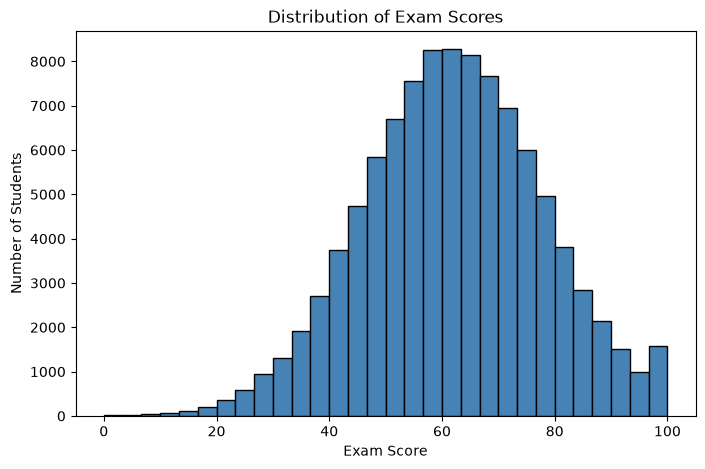

count    100000.00
mean         61.95
std          15.86
min           0.00
25%          51.24
50%          61.96
75%          72.73
max         100.00
Name: exam_score, dtype: float64

Pass/Fail share:
pass_status
Pass    0.774
Fail    0.226
Name: proportion, dtype: float64

Grade counts:
performance_grade
A     7519
B    13190
C    21794
D    34886
F    22611
Name: count, dtype: int64


In [6]:
### 6. The Target: Exam Score
# The target is `exam_score`, the value we want to predict. Its histogram is roughly bell-shaped, which suits regression. 
# We also look at the pass/fail split: about 22% of students fail. 
# This is important later, because the early-warning system is mainly about catching that minority.
    
plt.figure(figsize=(8, 5))
plt.hist(df["exam_score"], bins=30, color="steelblue", edgecolor="black")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.title("Distribution of Exam Scores")
plt.show()

print(df["exam_score"].describe().round(2))
print("\nPass/Fail share:")
print(df["pass_status"].value_counts(normalize=True).round(3))
print("\nGrade counts:")
print(df["performance_grade"].value_counts().sort_index())

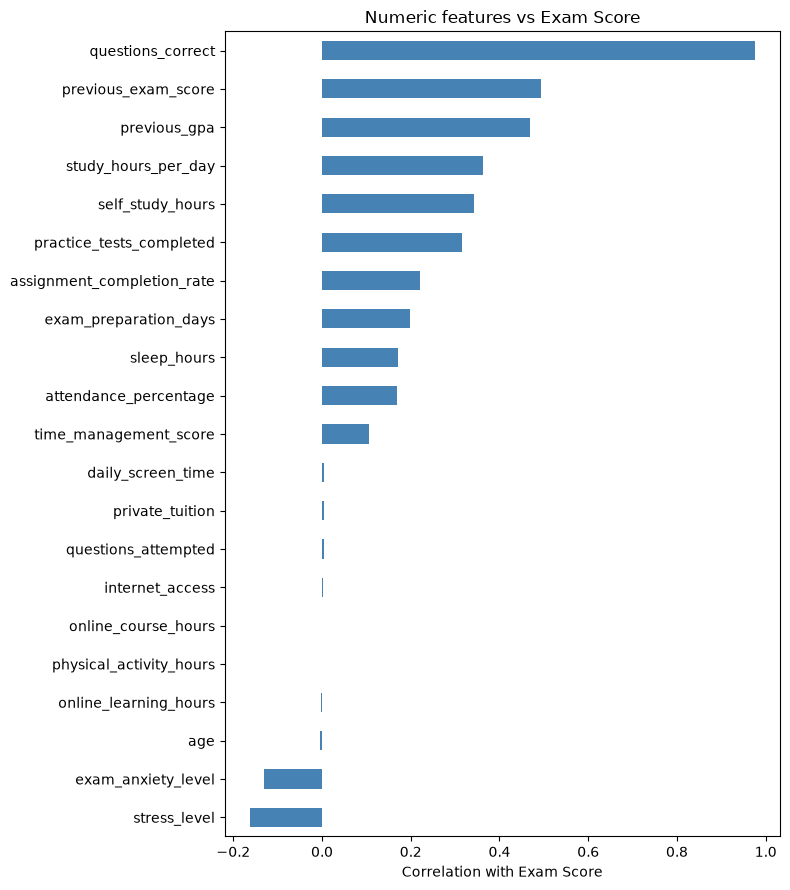

stress_level                 -0.162
exam_anxiety_level           -0.130
age                          -0.003
online_learning_hours        -0.003
physical_activity_hours      -0.000
online_course_hours           0.001
internet_access               0.002
questions_attempted           0.004
private_tuition               0.004
daily_screen_time             0.005
time_management_score         0.107
attendance_percentage         0.169
sleep_hours                   0.171
exam_preparation_days         0.199
assignment_completion_rate    0.221
practice_tests_completed      0.316
self_study_hours              0.343
study_hours_per_day           0.363
previous_gpa                  0.468
previous_exam_score           0.494
questions_correct             0.975
Name: exam_score, dtype: float64

In [7]:
### 7. Which Factors Relate to the Score?
# Correlation tells us how strongly each numeric column moves together with the exam score (-1 to +1). Previous exam score, previous GPA and study hours are the strongest legitimate factors. Stress and anxiety are negative. Screen time and online hours are near zero. 
# One column (`questions_correct`) has a correlation of about 0.97, which is a warning sign explained below.
    
corr = df[num_cols].corr()["exam_score"].drop("exam_score").sort_values()

plt.figure(figsize=(8, 9))
corr.plot(kind="barh", color="steelblue")
plt.xlabel("Correlation with Exam Score")
plt.title("Numeric features vs Exam Score")
plt.tight_layout()
plt.show()

display(corr.round(3))

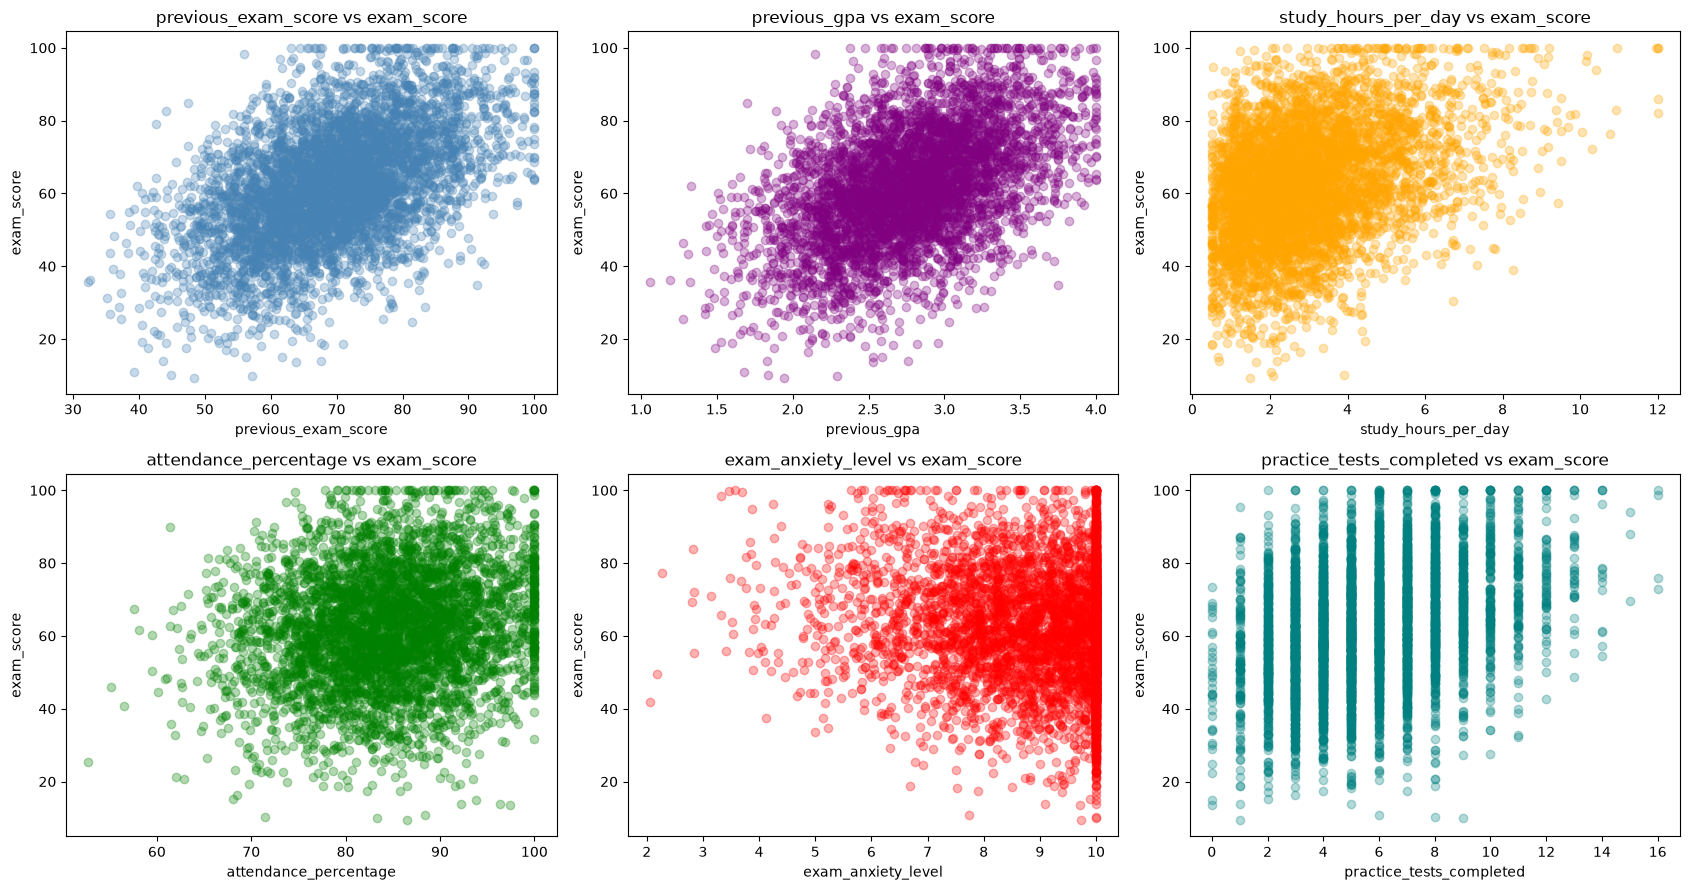

In [8]:
### 8. Key Factors vs Exam Score
# Scatter plots show each important factor against the score. The upward trend is visible but the points are spread out like a cloud. 
# That spread is natural noise in the data and is the reason a realistic model cannot reach 100% accuracy.
    
s = df.sample(5000, random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
pairs = [
    ("previous_exam_score", "steelblue"),
    ("previous_gpa", "purple"),
    ("study_hours_per_day", "orange"),
    ("attendance_percentage", "green"),
    ("exam_anxiety_level", "red"),
    ("practice_tests_completed", "teal"),
]
for ax, (col, color) in zip(axes.ravel(), pairs):
    ax.scatter(s[col], s["exam_score"], alpha=0.3, color=color)
    ax.set_xlabel(col)
    ax.set_ylabel("exam_score")
    ax.set_title(f"{col} vs exam_score")
plt.tight_layout()
plt.show()

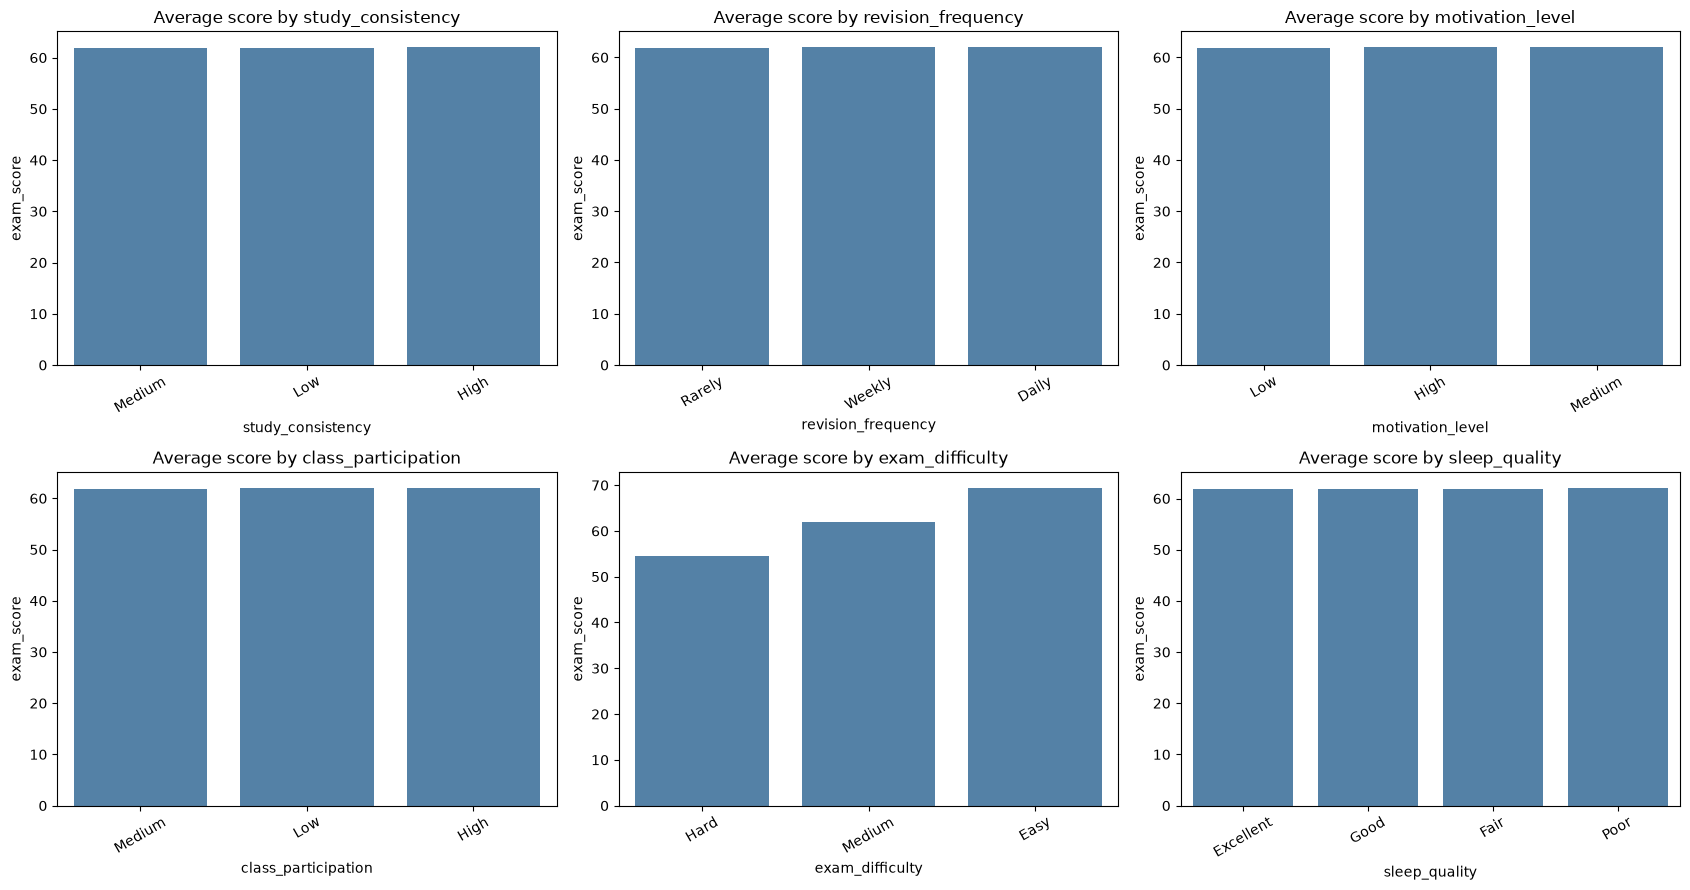

In [9]:
### 9. Average Score by Category
# Bar charts show the average score for each category of a text column, such as study consistency or exam difficulty. 
# Higher consistency and easier papers go with higher scores. Exam difficulty also turns out to be one of the model's top factors later.

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.ravel(), ["study_consistency", "revision_frequency", "motivation_level",
                                  "class_participation", "exam_difficulty", "sleep_quality"]):
    order = df.groupby(col)["exam_score"].mean().sort_values().index
    sns.barplot(data=df, x=col, y="exam_score", order=order, ax=ax, errorbar=None, color="steelblue")
    ax.set_title(f"Average score by {col}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

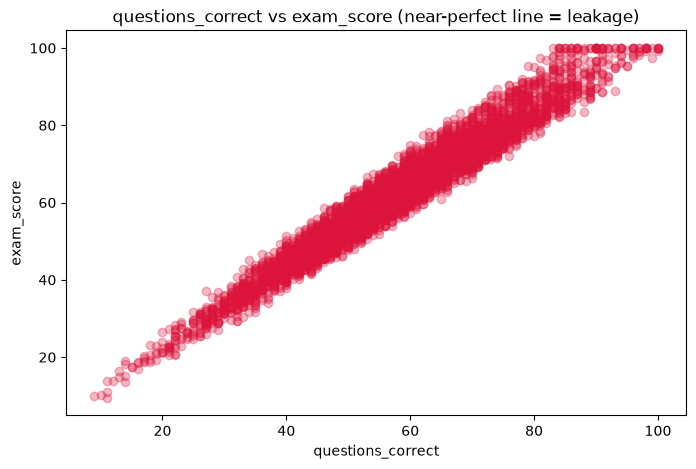

Correlation (questions_correct vs exam_score): 0.975

stress_level == 10 : 69.9%
exam_anxiety >= 10 : 38.6%


In [10]:
### 10. Data Leakage and Dataset Limitations
# **Leakage** means giving the model information it would not have before the exam. 
# `questions_correct` forms an almost perfect straight line with the score, because it is essentially the score itself. 
# Grade, pass status and performance level are also computed from the score. We remove all of these. Otherwise the model would look perfect but be useless in real life.

# **Limitations:** `stress_level` is at the maximum (10) for about 70% of students and `exam_anxiety_level` is capped at 10 for about 39%. 
# The dataset appears to be synthetic, so the results show the method works, not exact real-world accuracy.
    
sample_leak = df.sample(5000, random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(sample_leak["questions_correct"], sample_leak["exam_score"], alpha=0.3, color="crimson")
plt.xlabel("questions_correct")
plt.ylabel("exam_score")
plt.title("questions_correct vs exam_score (near-perfect line = leakage)")
plt.show()

print("Correlation (questions_correct vs exam_score):", round(df["questions_correct"].corr(df["exam_score"]), 3))
print()
print("stress_level == 10 :", f"{(df['stress_level'] == 10).mean():.1%}")
print("exam_anxiety >= 10 :", f"{(df['exam_anxiety_level'] >= 10).mean():.1%}")

# PART B: Modelling

In [ ]:
## Part B: Module 1 (Score Prediction)
# We now build and compare machine learning models that predict the exam score from information available before the exam.

In [11]:
### 11. Inputs, Target and Train/Test Split
# `X` holds the input columns and `y` is the exam score. We drop the leakage columns and the student ID.
# The data is split 80% for training and 20% for testing. 
# The model learns only from the training part, and the test part stays hidden so that we can measure how well it does on students it has never seen.
    
TARGET = "exam_score"

LEAKAGE = ["student_id", "questions_attempted", "questions_correct",
           "performance_grade", "pass_status", "performance_level"]

X = df.drop(columns=[TARGET] + LEAKAGE)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# test students ki original rows (risk checking ke liye later)
test_info = df.loc[X_test.index].copy()

print("X shape:", X.shape)
print("Train:", X_train.shape, "| Test:", X_test.shape)

X shape: (100000, 37)
Train: (80000, 37) | Test: (20000, 37)


In [12]:
### 12. Preprocessing Pipeline
# Models only understand numbers and cannot handle gaps. 
# The pipeline therefore (1) fills missing numbers with the median and scales them to a common range, 
# and (2) fills missing text with the most common value and converts categories into 0/1 columns (one-hot encoding). 
# It learns these rules from the training data only and then applies them to the test data, so no information leaks from the test set.

num_features = X_train.select_dtypes(include=np.number).columns.tolist()
cat_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_tf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_tf = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_tf, num_features),
    ("cat", categorical_tf, cat_features)
])

print(len(num_features), "numeric |", len(cat_features), "categorical")

19 numeric | 18 categorical


In [13]:
### 13. Training and Comparing Models
# We train six models: a Dummy baseline (always predicts the average), Linear Regression, Decision Tree, Random Forest, Gradient Boosting and HistGradientBoosting. We measure each with:
# - **MAE:** the average error in marks (MAE 7 means predictions are about 7 marks off)
# - **RMSE:** like MAE but punishes big mistakes more
# - **R²:** the share of score variation the model explains (0 = no better than guessing the average, 1 = perfect)

# The Dummy model is the baseline. Every real model must beat it to prove it learned something. Boosting models are the best (R² about 0.66, MAE about 7.3), only slightly ahead of Linear Regression.
    
models = {
    "Dummy (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, random_state=42),
}

trained, rows = {}, []

for name, model in models.items():
    print("Training", name, "...")
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    trained[name] = pipe
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

results = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
print("\nModel comparison (sorted by RMSE):")
display(results.round(3))

Training Dummy (mean) ...
Training Linear Regression ...
Training Decision Tree ...
Training Random Forest ...
Training Gradient Boosting ...
Training HistGradientBoosting ...

Model comparison (sorted by RMSE):


,Model,MAE,RMSE,R2
0,Gradient Boosting,7.318,9.165,0.662
1,HistGradientBoosting,7.356,9.201,0.659
2,Random Forest,7.569,9.472,0.639
3,Linear Regression,7.566,9.495,0.637
4,Decision Tree,8.674,10.859,0.526
5,Dummy (mean),12.622,15.768,-0.000


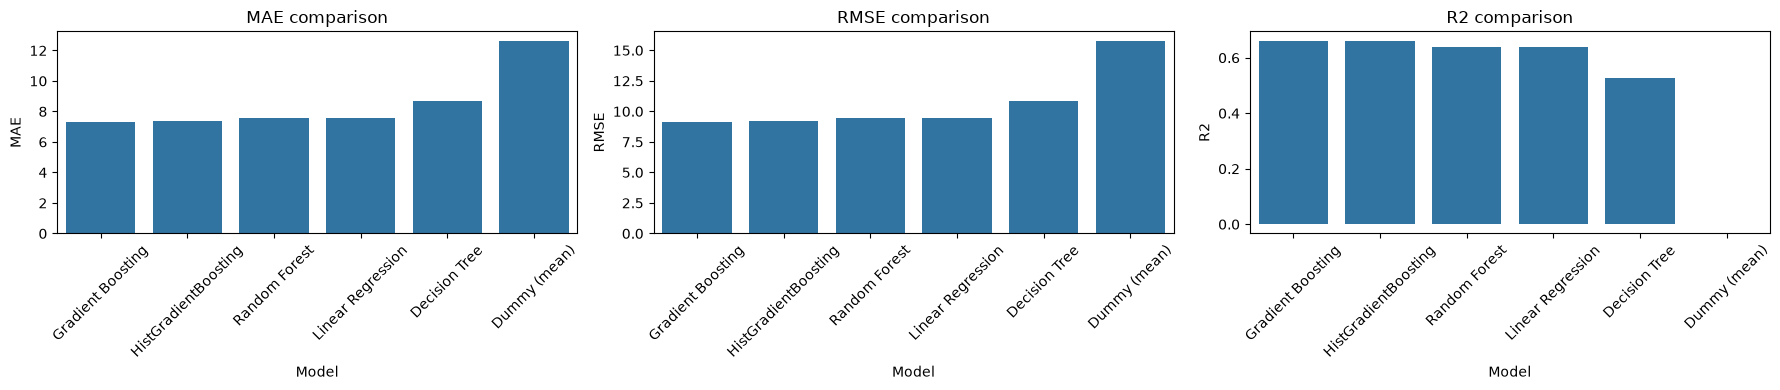

In [14]:
### 14. Model Comparison Charts
# The same results as bar charts for easier comparison. Lower MAE/RMSE and higher R² are better.
    
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    sns.barplot(data=results, x="Model", y=metric, ax=ax)
    ax.set_title(f"{metric} comparison")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [15]:
# ### 15. Hyperparameter Tuning
# Hyperparameters are model settings (such as learning rate and tree depth) that are chosen before training. 
# Instead of guessing, we try several random combinations using 3-fold cross-validation on the training data only, then keep the best. 
# We used HistGradientBoosting because it is much faster than Gradient Boosting with almost the same accuracy. 
# Tuning did not change the result much, which shows the model has reached the limit set by the noise in this dataset.
    
gb_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingRegressor(random_state=42))
])

param_dist = {
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_iter": [200, 300],
    "model__max_depth": [3, 5, None],
    "model__min_samples_leaf": [20, 50, 100],
}

search = RandomizedSearchCV(
    gb_pipe, param_dist,
    n_iter=6,
    cv=KFold(3, shuffle=True, random_state=42),
    scoring="neg_root_mean_squared_error",
    n_jobs=1, random_state=42, verbose=2
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best CV RMSE:", round(-search.best_score_, 3))

best_model = search.best_estimator_

Fitting 3 folds for each of 6 candidates, totalling 18 fits
[CV] END model__learning_rate=0.05, model__max_depth=3, model__max_iter=200, model__min_samples_leaf=50; total time=   5.5s
[CV] END model__learning_rate=0.05, model__max_depth=3, model__max_iter=200, model__min_samples_leaf=50; total time=   5.4s
[CV] END model__learning_rate=0.05, model__max_depth=3, model__max_iter=200, model__min_samples_leaf=50; total time=   5.3s
[CV] END model__learning_rate=0.1, model__max_depth=None, model__max_iter=200, model__min_samples_leaf=50; total time=   6.9s
[CV] END model__learning_rate=0.1, model__max_depth=None, model__max_iter=200, model__min_samples_leaf=50; total time=   6.1s
[CV] END model__learning_rate=0.1, model__max_depth=None, model__max_iter=200, model__min_samples_leaf=50; total time=   7.2s
[CV] END model__learning_rate=0.1, model__max_depth=None, model__max_iter=200, model__min_samples_leaf=20; total time=   7.1s
[CV] END model__learning_rate=0.1, model__max_depth=None, model_

MAE : 7.350
RMSE: 9.208
R2  : 0.659


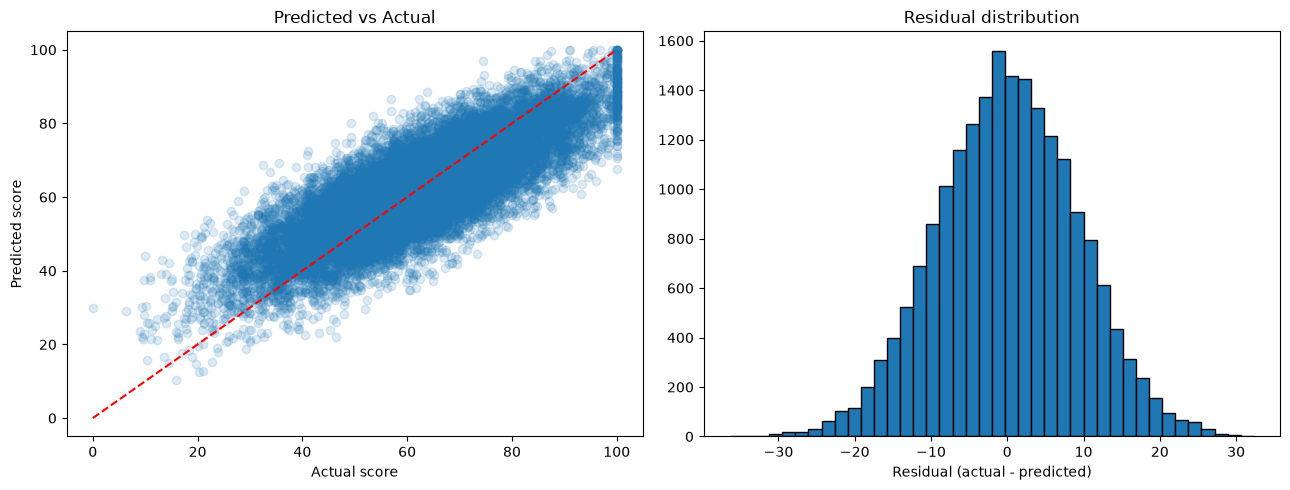

In [16]:
### 16. Final Evaluation on the Hidden Test Set
# This is the honest score: the tuned model predicting students it has never seen. Predictions are limited to 0 to 100. 
# The "Predicted vs Actual" plot shows points around the red diagonal line (perfect predictions). 
# The residual histogram shows the errors. It is centred on zero and bell-shaped, meaning the model is not biased towards over- or under-predicting.

pred_test = np.clip(best_model.predict(X_test), 0, 100)

print(f"MAE : {mean_absolute_error(y_test, pred_test):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, pred_test)):.3f}")
print(f"R2  : {r2_score(y_test, pred_test):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, pred_test, alpha=0.15)
axes[0].plot([0, 100], [0, 100], "r--")
axes[0].set(xlabel="Actual score", ylabel="Predicted score", title="Predicted vs Actual")

axes[1].hist(y_test - pred_test, bins=40, edgecolor="black")
axes[1].set(xlabel="Residual (actual - predicted)", title="Residual distribution")

plt.tight_layout()
plt.show()

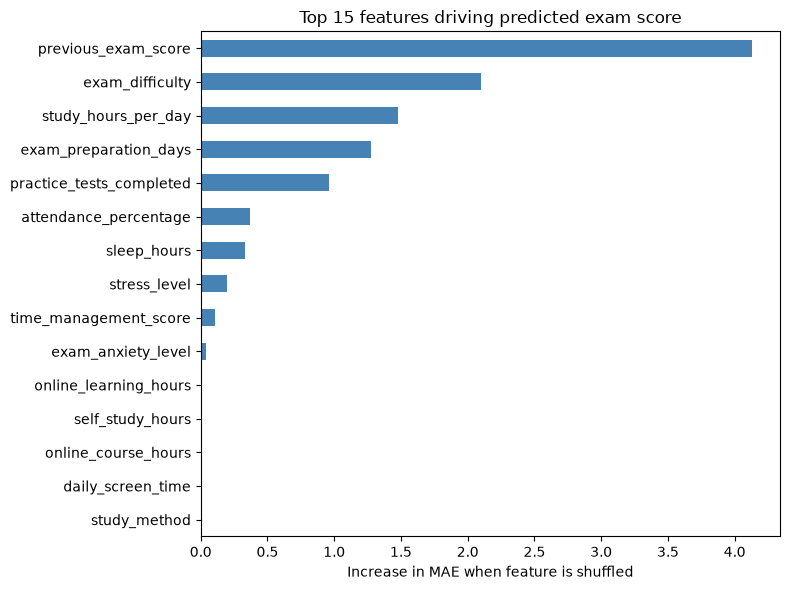

In [17]:
# ### 17. Which Factors Drive the Prediction?
# Permutation importance shuffles one column at a time and measures how much worse the predictions become. 
# A big drop means the model depends heavily on that factor. Previous exam score, exam difficulty, study hours, preparation days and practice tests matter most.
# Columns such as screen time have almost no effect. This tells teachers which factors are worth acting on.
    
sample_idx = X_test.sample(5000, random_state=42).index

perm = permutation_importance(
    best_model, X_test.loc[sample_idx], y_test.loc[sample_idx],
    n_repeats=5, random_state=42, n_jobs=-1,
    scoring="neg_mean_absolute_error"
)

imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

imp.tail(15).plot(kind="barh", figsize=(8, 6), color="steelblue")
plt.xlabel("Increase in MAE when feature is shuffled")
plt.title("Top 15 features driving predicted exam score")
plt.tight_layout()
plt.show()

In [ ]:
## Module 2: Risk Flagging and Recommendations
# A predicted score alone is not enough for a teacher. This module turns it into a clear action list.

In [18]:
### 18. Early-Warning Risk Levels
# Each student's predicted score is converted into High, Medium or Low risk using two thresholds (High below 50, Medium below 60). 
# The thresholds sit around the pass mark of 50 with a safety margin, because predictions are off by about 7 marks on average. 
# We then check the flags against what really happened: the High Risk group should have a much higher real failure rate than the Low Risk group.
# We also measure **recall** (what share of real failures we caught) and **precision** (what share of flagged students really failed). 
# Moving the thresholds trades one against the other.
    
HIGH_T, MEDIUM_T = 50, 60

def risk_level(score):
    if score < HIGH_T:
        return "High Risk"
    elif score < MEDIUM_T:
        return "Medium Risk"
    return "Low Risk"

test_info["predicted_score"] = pred_test
test_info["risk_level"] = test_info["predicted_score"].apply(risk_level)

summary = (test_info.groupby("risk_level")
           .agg(students=("exam_score", "size"),
                avg_actual_score=("exam_score", "mean"),
                actual_fail_rate=("pass_status", lambda s: (s == "Fail").mean()))
           .reindex(["High Risk", "Medium Risk", "Low Risk"]))
display(summary.round(3))

failed = test_info["pass_status"] == "Fail"
flagged_high = test_info["risk_level"] == "High Risk"
flagged_any = test_info["risk_level"] != "Low Risk"

print("\nActual failures in test set:", failed.sum())
print(f"Caught by High Risk only (recall): {(failed & flagged_high).sum() / failed.sum():.1%}")
print(f"Caught by High + Medium (recall) : {(failed & flagged_any).sum() / failed.sum():.1%}")
print(f"Precision of High Risk flag      : {(failed & flagged_high).sum() / flagged_high.sum():.1%}")

,students,avg_actual_score,actual_fail_rate
risk_level,,,
High Risk,3477,43.150,0.730
Medium Risk,5251,55.338,0.291
Low Risk,11272,71.089,0.035



Actual failures in test set: 4464
Caught by High Risk only (recall): 56.9%
Caught by High + Medium (recall) : 91.1%
Precision of High Risk flag      : 73.0%


In [19]:
### 20. Recommendation Rules
# Each rule checks one concern (for example attendance below 75% or sleep under 6 hours) and attaches a suggested action. 
# These are rule-based and use fixed cut-offs chosen by us, not learned from data. 
# They are a starting point. Teachers review them and decide the real intervention.
    
RULES = [
    ("attendance_percentage",      lambda v: v < 75,   "Attendance below 75% -> monitor attendance, contact parents/guardian"),
    ("assignment_completion_rate", lambda v: v < 60,   "Low assignment completion -> assignment tracking and reminders"),
    ("study_hours_per_day",        lambda v: v < 2,    "Very low daily study time -> structured study schedule"),
    ("practice_tests_completed",   lambda v: v < 4,    "Few practice tests -> assign additional practice sessions"),
    ("time_management_score",      lambda v: v < 65,   "Weak time management -> time-management workshop / planner"),
    ("sleep_hours",                lambda v: v < 6,    "Under 6 hours sleep -> sleep-hygiene guidance"),
    ("exam_anxiety_level",         lambda v: v >= 9.5, "High exam anxiety -> counselling / exam-stress support"),
    ("previous_exam_score",        lambda v: v < 55,   "Low previous score -> remedial guidance / mentoring"),
    ("revision_frequency",         lambda v: v == "Rarely", "Rare revision -> weekly revision plan"),
    ("study_consistency",          lambda v: v == "Low",    "Inconsistent study habits -> daily routine / mentor check-ins"),
    ("class_participation",        lambda v: v == "Low",    "Low participation -> encourage engagement, peer-learning groups"),
]

def recommend(row, max_items=4):
    recs = []
    for col, condition, text in RULES:
        value = row.get(col)
        if pd.notna(value) and condition(value):
            recs.append(text)
    return recs[:max_items] if recs else ["No specific concern found - continue monitoring"]

In [20]:
### 21. Teacher Dashboard Table
# The rules are applied to flagged students and the list is sorted with the lowest predicted score first, so the students who need help most appear at the top.
# The sample report at the bottom shows what a teacher would see for one student: predicted score, risk level and recommended actions.
    
at_risk = test_info[test_info["risk_level"] != "Low Risk"].copy()
at_risk["recommendations"] = at_risk.apply(recommend, axis=1)
print(len(at_risk), "students flagged out of", len(test_info))

dashboard = (at_risk
             .sort_values("predicted_score")
             [["student_id", "predicted_score", "risk_level", "previous_exam_score",
               "attendance_percentage", "assignment_completion_rate", "recommendations"]]
             .reset_index(drop=True))
dashboard["predicted_score"] = dashboard["predicted_score"].round(1)

print("\nTop 10 students needing attention:")
display(dashboard.head(10))

top = dashboard.iloc[0]
print("\n--- Sample student report ---")
print("Student        :", top["student_id"])
print("Predicted score:", top["predicted_score"], f"({top['risk_level']})")
print("Recommended actions:")
for r in top["recommendations"]:
    print("  -", r)

8728 students flagged out of 20000

Top 10 students needing attention:


,student_id,predicted_score,risk_level,previous_exam_score,attendance_percentage,assignment_completion_rate,recommendations
0,STU_054892,10.4,High Risk,51.05,73.84,67.29,"[Attendance below 75% -> monitor attendance, c..."
1,STU_061989,12.6,High Risk,52.93,78.06,61.01,[Very low daily study time -> structured study...
2,STU_023196,12.8,High Risk,43.26,90.01,76.03,[Very low daily study time -> structured study...
3,STU_035577,14.6,High Risk,48.98,68.27,52.15,"[Attendance below 75% -> monitor attendance, c..."
4,STU_012718,14.8,High Risk,45.67,70.82,65.12,"[Attendance below 75% -> monitor attendance, c..."
5,STU_029324,15.2,High Risk,35.25,77.43,58.94,[Low assignment completion -> assignment track...
6,STU_013941,15.8,High Risk,39.14,59.93,34.89,"[Attendance below 75% -> monitor attendance, c..."
7,STU_054315,16.5,High Risk,40.31,77.00,61.34,[Very low daily study time -> structured study...
8,STU_060807,16.7,High Risk,55.13,78.67,61.24,[Very low daily study time -> structured study...
9,STU_070831,17.6,High Risk,33.98,74.00,63.80,"[Attendance below 75% -> monitor attendance, c..."



--- Sample student report ---
Student        : STU_054892
Predicted score: 10.4 (High Risk)
Recommended actions:
  - Attendance below 75% -> monitor attendance, contact parents/guardian
  - Very low daily study time -> structured study schedule
  - High exam anxiety -> counselling / exam-stress support
  - Low previous score -> remedial guidance / mentoring


In [21]:
### 22. Saving the Model and Results
# The trained model is saved as `performiq_model.joblib`, so it can be loaded later (for example by the backend or dashboard) without retraining. 
# The flagged-student list is saved as a CSV.
    
joblib.dump(best_model, "performiq_model.joblib")
dashboard.to_csv("performiq_at_risk_students.csv", index=False)
print("Saved: performiq_model.joblib, performiq_at_risk_students.csv")

Saved: performiq_model.joblib, performiq_at_risk_students.csv


In [22]:
# ---- Threshold experiment: flagged % vs recall vs precision ----
rows = []
for t in [45, 50, 55, 60, 65, 70]:
    flagged = test_info["predicted_score"] < t
    rows.append({
        "threshold": t,
        "flagged_%": flagged.mean() * 100,
        "recall_%": (failed & flagged).sum() / failed.sum() * 100,
        "precision_%": (failed & flagged).sum() / flagged.sum() * 100,
    })
display(pd.DataFrame(rows).round(1))

,threshold,flagged_%,recall_%,precision_%
0,45,8.9,33.9,84.7
1,50,17.4,56.9,73.0
2,55,29.2,76.9,58.9
3,60,43.6,91.1,46.6
4,65,59.2,97.6,36.8
5,70,73.1,99.6,30.4


In [ ]:
# ## Summary of Results
# - **Best model:** (add your final model and its MAE / RMSE / R² here)
# - **Top factors:** previous exam score, exam difficulty, study hours, preparation days, practice tests
# - **Risk flags work:** (add your High vs Low Risk real failure rates and recall here)
# - **Limitations:** the dataset looks synthetic; stress and anxiety are capped at 10; 
# each student has only one exam, so trends over time cannot be studied here. 
# That is covered in Module 3.